# Homework 3: Machine Learning for Classification (ML Zoomcamp 2026)

Predicting whether a lead **converts** (signs up to the platform) on the pinned 2026
lead-scoring dataset, using logistic regression with one-hot encoding as in module 03.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, mutual_info_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

Path('images').mkdir(exist_ok=True)

## Data

In [2]:
DATA_URL = ('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/'
            'main/cohorts/2026/data/course_lead_scoring_2026.csv')
LOCAL = Path('../../../data/course_lead_scoring_2026.csv')
df = pd.read_csv(LOCAL if LOCAL.exists() else DATA_URL)
print(df.shape)
df.head()

(5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
TARGET = 'converted'
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

### Data preparation

Missing values exist in 6 of 9 columns. Categorical → `'NA'`, numerical → `0.0`.

In [4]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [5]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)
assert df.isnull().sum().sum() == 0
df[TARGET].value_counts(normalize=True)

converted
1    0.5766
0    0.4234
Name: proportion, dtype: float64

Classes are mildly imbalanced (≈58% converted), so the majority-class baseline accuracy is ≈0.58–0.60.

## Q1. Mode of `industry`

In [6]:
df.industry.value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

In [7]:
df.industry.mode()[0]

'technology'

**Answer: `technology`** (1,173 rows). The filled `'NA'` category has only 240.

## Q2. Biggest correlation

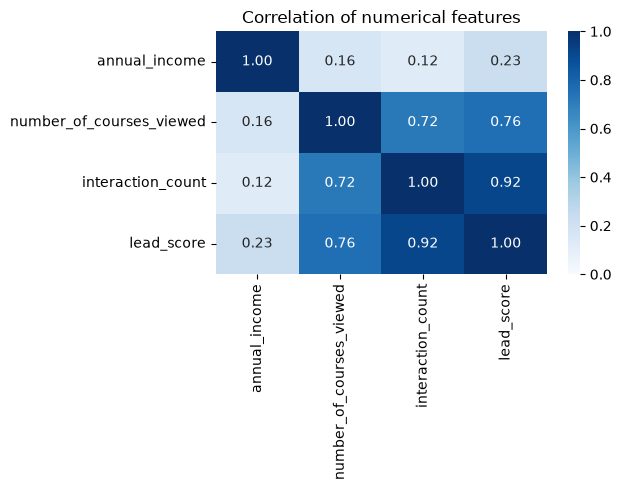

In [8]:
corr = df[numerical].corr()

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax)
ax.set_title('Correlation of numerical features')
plt.tight_layout(); plt.savefig('images/correlation_matrix.png', dpi=120); plt.show()

In [9]:
pairs = [('interaction_count', 'lead_score'),
         ('number_of_courses_viewed', 'lead_score'),
         ('number_of_courses_viewed', 'interaction_count'),
         ('annual_income', 'interaction_count')]
pd.Series({f'{a} & {b}': corr.loc[a, b] for a, b in pairs}).sort_values(ascending=False).round(4)

interaction_count & lead_score                  0.9157
number_of_courses_viewed & lead_score           0.7572
number_of_courses_viewed & interaction_count    0.7216
annual_income & interaction_count               0.1228
dtype: float64

**Answer: `interaction_count` and `lead_score`** (r = 0.916). `lead_score` looks like it is largely derived from engagement.

## Split the data

In [10]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.pop(TARGET).values
y_val = df_val.pop(TARGET).values
y_test = df_test.pop(TARGET).values

assert TARGET not in df_train.columns
len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Q3. Mutual information (train only)

In [11]:
mi = pd.Series({c: mutual_info_score(y_train, df_train[c]) for c in categorical}).sort_values(ascending=False)
print(mi.round(4))
print()
print(mi.apply(lambda s: round(s, 2)))

lead_source          0.0343
employment_status    0.0190
industry             0.0020
location             0.0010
dtype: float64

lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64


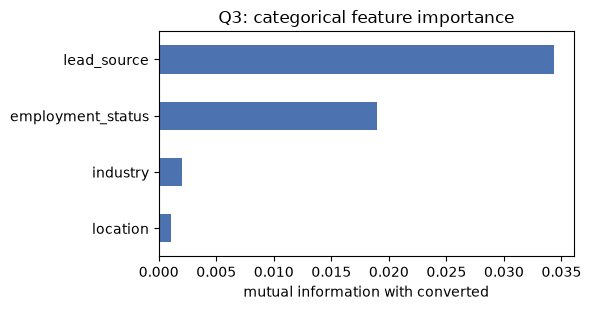

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.2))
mi.sort_values().plot.barh(ax=ax, color='#4C72B0')
ax.set_xlabel('mutual information with converted'); ax.set_title('Q3: categorical feature importance')
plt.tight_layout(); plt.savefig('images/mutual_information.png', dpi=120); plt.show()

**Answer: `lead_source`** (0.03). `industry` and `location` carry essentially no signal (≈0.00).

## Q4. Logistic regression

In [13]:
features = categorical + numerical

def train_and_score(df_tr, y_tr, df_v, y_v, feats, C=1.0, return_model=False):
    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_tr[feats].to_dict(orient='records'))
    X_v = dv.transform(df_v[feats].to_dict(orient='records'))
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    model.fit(X_tr, y_tr)
    acc = accuracy_score(y_v, model.predict(X_v))
    return (acc, dv, model, X_v) if return_model else acc

base_acc, dv, model, X_val = train_and_score(df_train, y_train, df_val, y_val, features, return_model=True)
base_acc, round(base_acc, 2)

(0.645, 0.65)

**Answer: 0.65** (0.645).

## Q5. Feature elimination

In [14]:
rows = []
for f in features:
    acc = train_and_score(df_train, y_train, df_val, y_val, [x for x in features if x != f])
    rows.append({'feature': f, 'acc_without': acc, 'diff': base_acc - acc})
elim = pd.DataFrame(rows).set_index('feature').sort_values('diff')
elim.round(4)

,acc_without,diff
feature,,
annual_income,0.724,-0.079
industry,0.645,0.000
location,0.645,0.000
employment_status,0.645,0.000
lead_score,0.644,0.001
number_of_courses_viewed,0.643,0.002
lead_source,0.642,0.003
interaction_count,0.601,0.044


In [15]:
elim.loc[['lead_source', 'number_of_courses_viewed', 'interaction_count']].round(4)

,acc_without,diff
feature,,
lead_source,0.642,0.003
number_of_courses_viewed,0.643,0.002
interaction_count,0.601,0.044


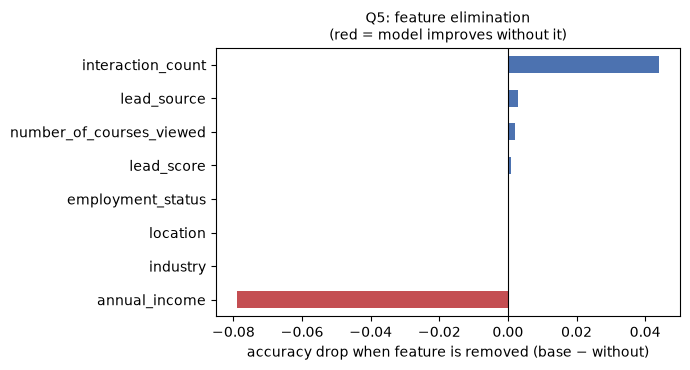

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.8))
colors = ['#C44E52' if d < 0 else '#4C72B0' for d in elim['diff']]
elim['diff'].plot.barh(ax=ax, color=colors)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('accuracy drop when feature is removed (base − without)')
ax.set_title('Q5: feature elimination\n(red = model improves without it)', fontsize=10); ax.set_ylabel('')
plt.tight_layout(); plt.savefig('images/feature_elimination.png', dpi=120); plt.show()

**Answer: `number_of_courses_viewed`** (diff 0.002, vs 0.003 for `lead_source` and 0.044 for `interaction_count`).

Something else stands out: **removing `annual_income` *improves* accuracy from 0.645 to 0.724**.
That's a scaling problem, not a useless feature. See the investigation below.

## Q6. Regularization

In [17]:
c_scores = {C: round(train_and_score(df_train, y_train, df_val, y_val, features, C=C), 3)
            for C in [0.000001, 0.00001, 0.0001, 0.001]}
c_scores

{1e-06: 0.598, 1e-05: 0.598, 0.0001: 0.613, 0.001: 0.645}

In [18]:
best = max(c_scores.values())
min(C for C, s in c_scores.items() if s == best)

0.001

**Answer: C = 0.001** (0.645). Smaller C means stronger L2 regularization. At C ≤ 1e-5 the weights are
crushed toward zero and accuracy falls to 0.598, which is roughly the majority-class rate in validation (0.597).

## Going further: why does dropping `annual_income` help?

`annual_income` is in the tens of thousands, while every other feature is 0–1 (one-hot, `lead_score`) or
single digits. Logistic regression (and its L2 penalty) is not scale invariant, so one huge raw feature
makes the liblinear optimisation badly conditioned. The model ends up predicting "converted" for most leads:

In [19]:
w = pd.Series(model.coef_[0], index=dv.get_feature_names_out())
print('annual_income weight:', w['annual_income'])
print('share of val predicted as converted:', model.predict(X_val).mean().round(3), 'vs actual', y_val.mean().round(3))

annual_income weight: -4.578499850723277e-06
share of val predicted as converted: 0.874 vs actual 0.597


In [20]:
num_idx = [i for i, n in enumerate(dv.get_feature_names_out()) if n in numerical]
dv_all = DictVectorizer(sparse=False)
X_tr = dv_all.fit_transform(df_train[features].to_dict(orient='records'))
X_v = dv_all.transform(df_val[features].to_dict(orient='records'))
X_tr_s, X_v_s = X_tr.copy(), X_v.copy()
sc = StandardScaler().fit(X_tr[:, num_idx])
X_tr_s[:, num_idx] = sc.transform(X_tr[:, num_idx])
X_v_s[:, num_idx] = sc.transform(X_v[:, num_idx])

Cs = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10]
res = []
for C in Cs:
    m = lambda: LogisticRegression(solver='liblinear', C=C, max_iter=1000, random_state=42)
    res.append({'C': C,
                'raw': accuracy_score(y_val, m().fit(X_tr, y_train).predict(X_v)),
                'scaled': accuracy_score(y_val, m().fit(X_tr_s, y_train).predict(X_v_s))})
res = pd.DataFrame(res).set_index('C')
res.round(3)

,raw,scaled
C,,
0.000001,0.598,0.712
0.000010,0.598,0.712
0.000100,0.613,0.713
0.001000,0.645,0.717
0.010000,0.645,0.722
0.100000,0.645,0.727
1.000000,0.645,0.728
10.000000,0.645,0.729


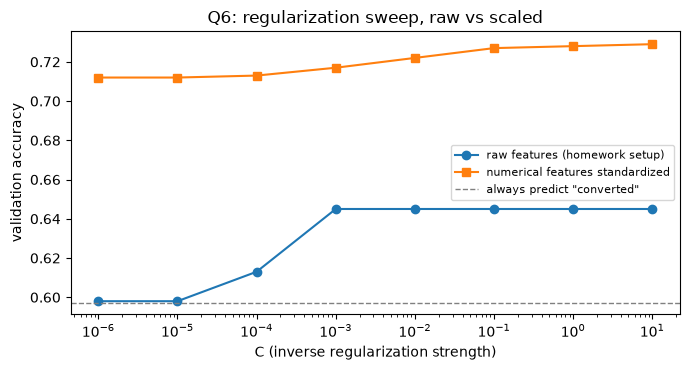

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(res.index, res['raw'], 'o-', label='raw features (homework setup)')
ax.plot(res.index, res['scaled'], 's-', label='numerical features standardized')
ax.axhline(y_val.mean(), ls='--', color='grey', lw=1, label='always predict "converted"')
ax.set_xscale('log'); ax.set_xlabel('C (inverse regularization strength)'); ax.set_ylabel('validation accuracy')
ax.set_title('Q6: regularization sweep, raw vs scaled'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('images/c_sweep_scaling.png', dpi=120); plt.show()

Standardizing the four numerical columns (scaler fit on train only) lifts validation accuracy from
**0.645 to 0.728** at C=1 and makes the model robust to C. Log-transforming income instead (`np.log1p`) gives 0.722.

**Takeaways**
1. Scale numerical features before logistic regression, especially when you use regularization.
2. Feature elimination results can mislead: a feature that "hurts" may just be badly scaled.
3. Always compare against the majority-class baseline (≈0.60 here). 0.645 is only a small gain over it.